# Theme analysis Plots

We will do some of our plots with Flourish. We just need to create the csv and export them in their online plateform to obtain results.

In [1]:
# general
import os
from pathlib import Path
import pandas as pd
import numpy as np
from tqdm import tqdm

# statistical test
from scipy import stats

from IPython.display import display
import statsmodels.api as sm
import statsmodels.formula.api as smf

import matplotlib.pyplot as plt

# Displaying flourish results
from IPython.display import HTML

# Custom imports
import utils.utils_themes_P3 as p3_utils

In [2]:
# General variables: paths
ROOT = Path("../../data/newyorker_caption_contest")
THEME_PATH = ROOT / "THEMES_RESULTS_V4" 

# Files paths
DOCS_PATH   = THEME_PATH / "docs_with_themes.csv"
GEN_LABELS_PATH = THEME_PATH / "Themes_V4_gen_labels.csv"
SIMILARITY_PATH = THEME_PATH / "theme_similarity_by_theme_id.csv"
TF_IDF_PATH = THEME_PATH / "TF_IDF_themes_scores.csv"
THEMES_PATH = THEME_PATH / "themes.csv"

# save all flourish csv and others
SAVE = False

print(f"THEME_PATH:      {THEME_PATH.resolve()}\n")
print(f"GEN_LABELS_PATH: {GEN_LABELS_PATH.resolve()}")
print(f"SIMILARITY_PATH: {SIMILARITY_PATH.resolve()}")
print(f"DOCS_PATH:       {DOCS_PATH.resolve()}")
print(f"TF_IDF_PATH:     {TF_IDF_PATH.resolve()}")
print(f"THEMES_PATH:     {THEMES_PATH.resolve()}")

THEME_PATH:      /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/THEMES_RESULTS_V4

GEN_LABELS_PATH: /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/THEMES_RESULTS_V4/Themes_V4_gen_labels.csv
SIMILARITY_PATH: /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/THEMES_RESULTS_V4/theme_similarity_by_theme_id.csv
DOCS_PATH:       /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/THEMES_RESULTS_V4/docs_with_themes.csv
TF_IDF_PATH:     /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/THEMES_RESULTS_V4/TF_IDF_themes_scores.csv
THEMES_PATH:     /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/THEMES_RESULTS_V4/themes.csv


In [3]:
# load all content with themes extraction csv
df_doc = p3_utils.load_docs_with_theme_csv(DOCS_PATH)
df_doc.head()

# This dataset contains the following columns:
# ["doc_id", "contest_id", "kind", "text", "clean_text",
#  "rank", "mean", "precision", "votes", "not_funny", "somewhat_funny", "funny",
#  "theme_id", "theme_label"]
# 
# example rows:
# doc_id,contest_id,kind,text,clean_text,rank,mean,precision,votes,not_funny,somewhat_funny,funny,theme_id,theme_label
# image_510,510,image,A man is relaxing on a city street. Others are going about their business and stepping on him as they pass. A man is just laying in the middle of the sidewalk. the street Why is he laying there? Bystander effect Crowd,man relax city street go business step pass man lay middle sidewalk street lay bystander effect crowd,,,,,,,,62,Train
# caption_510_0,510,caption,I'm a congressman--obstruction is my job.,congressman obstruction job,0.0,1.9130434782608696,0.0940223859061473,69.0,24.0,27.0,18.0,64,Election
# caption_510_1,510,caption,"I'm what they mean when they say, 'The middle class is getting stepped on.'",mean middle class step,1.0,1.8421052631578947,0.1913809142918546,19.0,8.0,6.0,5.0,53,Market
# caption_510_2,510,caption,Does this suit make me look flat?,suit look flat,2.0,1.711111111111111,0.1129146554544009,45.0,21.0,16.0,8.0,76,Clothing
# 
# kind: "image" or "caption"

,doc_id,contest_id,kind,text,clean_text,rank,mean,precision,votes,not_funny,somewhat_funny,funny,theme_id,theme_label
0,image_510,510,image,A man is relaxing on a city street. Others are...,man relax city street go business step pass ma...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62,Train
1,caption_510_0,510,caption,I'm a congressman--obstruction is my job.,congressman obstruction job,0.0,1.913043,0.094022,69.0,24.0,27.0,18.0,64,Election
2,caption_510_1,510,caption,"I'm what they mean when they say, 'The middle ...",mean middle class step,1.0,1.842105,0.191381,19.0,8.0,6.0,5.0,53,Market
3,caption_510_2,510,caption,Does this suit make me look flat?,suit look flat,2.0,1.711111,0.112915,45.0,21.0,16.0,8.0,76,Clothing
4,caption_510_3,510,caption,"When the right woman comes along, I'll know it.",right woman come know,3.0,1.625000,0.116657,32.0,15.0,14.0,3.0,45,Marriage


In [4]:
# load generated label dictionary csv
gen_labels_cols = ["caption_id", "gen_label"]
df_tfidf = p3_utils.load_csv(GEN_LABELS_PATH, expected_cols=gen_labels_cols)

# rename 'caption_id' into 'theme_id' for clarity
df_tfidf = df_tfidf.rename(columns={"caption_id": "theme_id"})

# add generated labels to df_doc by matching on 'theme_id'
df_doc = df_doc.merge(df_tfidf, on="theme_id", how="left")

df_doc.head()

,doc_id,contest_id,kind,text,clean_text,rank,mean,precision,votes,not_funny,somewhat_funny,funny,theme_id,theme_label,gen_label
0,image_510,510,image,A man is relaxing on a city street. Others are...,man relax city street go business step pass ma...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62,Train,transport
1,caption_510_0,510,caption,I'm a congressman--obstruction is my job.,congressman obstruction job,0.0,1.913043,0.094022,69.0,24.0,27.0,18.0,64,Election,Trump
2,caption_510_1,510,caption,"I'm what they mean when they say, 'The middle ...",mean middle class step,1.0,1.842105,0.191381,19.0,8.0,6.0,5.0,53,Market,commerce
3,caption_510_2,510,caption,Does this suit make me look flat?,suit look flat,2.0,1.711111,0.112915,45.0,21.0,16.0,8.0,76,Clothing,apparel
4,caption_510_3,510,caption,"When the right woman comes along, I'll know it.",right woman come know,3.0,1.625000,0.116657,32.0,15.0,14.0,3.0,45,Marriage,marriage


In [5]:
# load theme_id similarity matrix from csv
similarity_df = pd.read_csv(SIMILARITY_PATH)
similarity_df.head()

# This df contains the cosine similarity matrix between themes id based on their clustered Sentence-BERT embeddings.
# 
# example rows:
# theme_id,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79
# 0,1.000000,0.402895,0.283682,0.362918,0.513067,0.381242,0.306716,0.410318,0.514566,0.487629,0.405967,0.336455,0.415770,0.246277,0.358432,0.445302,0.354353,0.448136,0.370220,0.151531,0.359336,0.322592,0.348809,0.354719,0.405969,0.386582,0.305997,0.432033,0.372474,0.270927,0.343026,0.385568,0.400781,0.474947,0.373683,0.423348,0.377090,0.393372,0.476460,0.240412,0.421958,0.315049,0.414474,0.660413,0.420147,0.406469,0.420728,0.318907,0.356792,0.456217,0.386815,0.396630,0.450809,0.365738,0.457646,0.436002,0.404623,0.691123,0.331228,0.354682,0.302393,0.319433,0.396411,0.459853,0.341526,0.335104,0.371577,0.443462,0.342810,0.364640,0.390853,0.302836,0.346689,0.398186,0.434105,0.443288,0.352182,0.412290,0.409759,0.365864
# 1,0.402895,1.000000,0.327793,0.487851,0.510671,0.472350,0.286405,0.509334,0.582684,0.430385,0.454279,0.403001,0.469207,0.276211,0.432070,0.610771,0.350142,0.471481,0.526179,0.274332,0.434553,0.373188,0.579625,0.333923,0.504686,0.422310,0.399627,0.566629,0.423269,0.386650,0.402884,0.430634,0.556866,0.472510,0.363390,0.346437,0.461152,0.490147,0.462971,0.231334,0.484749,0.321941,0.562304,0.465688,0.408749,0.450243,0.397447,0.362345,0.351394,0.548723,0.459192,0.342792,0.527025,0.354703,0.458411,0.533770,0.462489,0.468359,0.294511,0.368931,0.511314,0.483134,0.450247,0.356593,0.385245,0.331731,0.513318,0.526577,0.344344,0.420243,0.435116,0.420763,0.521627,0.557530,0.479820,0.442083,0.394563,0.537888,0.484329,0.518927


,theme_id,0,1,2,3,4,5,6,7,8,...,70,71,72,73,74,75,76,77,78,79
0,0,1.000000,0.402895,0.283682,0.362918,0.513067,0.381242,0.306716,0.410318,0.514566,...,0.390853,0.302836,0.346689,0.398186,0.434105,0.443288,0.352182,0.412290,0.409759,0.365864
1,1,0.402895,1.000000,0.327793,0.487851,0.510671,0.472350,0.286405,0.509334,0.582684,...,0.435116,0.420763,0.521627,0.557530,0.479820,0.442083,0.394563,0.537888,0.484329,0.518927
2,2,0.283682,0.327793,1.000000,0.334920,0.412829,0.288990,0.198154,0.415377,0.506217,...,0.373281,0.292525,0.543920,0.438732,0.419888,0.279726,0.359059,0.407414,0.328195,0.326667
3,3,0.362918,0.487851,0.334920,1.000000,0.462116,0.384542,0.223693,0.402566,0.454148,...,0.381653,0.299965,0.390584,0.384954,0.444621,0.408297,0.362750,0.436603,0.327778,0.328734
4,4,0.513067,0.510671,0.412829,0.462116,1.000001,0.525934,0.282231,0.605301,0.702932,...,0.561148,0.423270,0.488898,0.601121,0.545249,0.467601,0.494168,0.558372,0.527386,0.477060


In [6]:
# # load TF-IDF theme terms scores csv
# tfidf_cols = ["theme_id", "term", "sim", "local_freq", "global_freq", "distinctiveness", "score"]
# df_tfidf = p3_utils.load_csv(TF_IDF_PATH, expected_cols=tfidf_cols)
# df_tfidf.head()

In [7]:
# load the 80 themes id, terms and stats
themes_cols = ["theme_id", "theme_label", "nb_instances", "mu_rank", "mu_mean", "mu_precision",
               "mu_not_funny", "mu_somewhat_funny", "mu_funny", "TF_IDF_terms"]
df_themes = p3_utils.load_csv(THEMES_PATH, expected_cols=themes_cols)
df_themes.head()

# this dataset contains statistics about each of the 80 themes extracted
# example rows:
# theme_id,theme_label,nb_instances,mu_rank,mu_mean,mu_precision,mu_not_funny,mu_somewhat_funny,mu_funny,TF_IDF_terms
# 0,Dog,28929,3221.119070667957,1.2117988825750874,0.047786328683020726,100.9608629511824,27.160904439220026,10.610150739870004,"dog, pet, bark, leash, puppy, animal, vet, know, collar, think"
# 1,Fall Asleep,18290,3005.3332057520915,1.2170834415838647,0.054424750814529826,93.6899775821532,27.131281097927715,11.584066925474328,"sleep, night, tired, dream, bed, wake, nap, asleep, morning, fall asleep"
# 
# Do not use the 'theme_labels' column, instead use the generated labels from df_doc from column 'gen_label'

,theme_id,theme_label,nb_instances,mu_rank,mu_mean,mu_precision,mu_not_funny,mu_somewhat_funny,mu_funny,TF_IDF_terms
0,0,Dog,28929,3221.119071,1.211799,0.047786,100.960863,27.160904,10.610151,"dog, pet, bark, leash, puppy, animal, vet, kno..."
1,1,Fall Asleep,18290,3005.333206,1.217083,0.054425,93.689978,27.131281,11.584067,"sleep, night, tired, dream, bed, wake, nap, as..."
2,2,Year,21754,3161.643560,1.226651,0.051957,98.822745,30.887515,13.722948,"year, month, season, fall, date, time, age, th..."
3,3,Work Home,35262,3162.187975,1.218767,0.055696,88.715088,25.710210,10.443817,"work, job, work home, home, office, say, think..."
4,4,Clown,22401,3421.341284,1.205269,0.051263,88.639421,21.413864,8.350485,"clown, circus, laugh, funny, cop, joke, tell, ..."


## Theme relations between images and captions

Sketch:

<img src="../../figures/sketches/graph_sketch.jpg" width="400">

In [8]:
# build flourish csv from df_doc
df_flourish = p3_utils.build_flourish_csv(df_doc)
df_flourish.head()


,Image_Theme,Caption_Theme,count,funny_score,image_theme_id,caption_theme_id
0,T0: dog,T0: dog,5109,1.210768,0,0
1,T0: dog,T1: sleep,122,1.225362,0,1
2,T0: dog,T2: time,352,1.214082,0,2
3,T0: dog,T3: work,509,1.291094,0,3
4,T0: dog,T4: comedy,278,1.192333,0,4


In [9]:
flourish_out_path = Path("../../data/newyorker_caption_contest/FLOURISH/flourish_heatmap.csv").resolve()
flourish_3_out_path = Path("../../data/newyorker_caption_contest/FLOURISH/flourish_heatmap3.csv").resolve()

if SAVE:
    df_flourish.to_csv(flourish_out_path, index=False)
    print("Flourish csv saved at: ", flourish_out_path)

In [10]:
# Size reduction for graph readability

TOP_THEMES_PER_SIDE = 15   # keep top N nodes per side; rest -> removed
TOP_LINKS_PER_SOURCE = 5   # keep top K outgoing links per Source
MIN_VALUE = 1500             # drop links below this after aggregation
DROP_SELF_LINKS = False    # Source!=Target only if True

df_f = df_flourish.copy()

# optional: remove self-links
if DROP_SELF_LINKS:
    df_f = df_f[df_f["Image_Theme"] != df_f["Caption_Theme"]].copy()

# keep only top nodes on each side (by total flow)
top_sources = (df_f.groupby("Image_Theme")["count"].sum().nlargest(TOP_THEMES_PER_SIDE).index)
top_targets = (df_f.groupby("Caption_Theme")["count"].sum().nlargest(TOP_THEMES_PER_SIDE).index)

df_f = df_f[df_f["Image_Theme"].isin(top_sources) & df_f["Caption_Theme"].isin(top_targets)].copy()

# drop tiny links
df_f = df_f[df_f["count"] >= MIN_VALUE].copy()

# keep only top K links per Source (within the retained nodes)
df_f = (df_f.sort_values(["Image_Theme", "count"], ascending=[True, False])
           .groupby("Image_Theme", as_index=False)
           .head(TOP_LINKS_PER_SOURCE)
           .reset_index(drop=True))

df_flourish_reduced = df_f

df_flourish_reduced.head()



,Image_Theme,Caption_Theme,count,funny_score,image_theme_id,caption_theme_id
0,T0: dog,T8: goodness,2395,1.193009,0,8
1,T0: dog,T76: apparel,1550,1.232084,0,76
2,T17: chivalry,T17: chivalry,10349,1.196902,17,17
3,T17: chivalry,T41: recruitment,3219,1.177498,17,41
4,T17: chivalry,T76: apparel,3063,1.214351,17,76


In [11]:
print("Length df_flourish:", len(df_flourish))
print("Length df_flourish_reduced:", len(df_flourish_reduced))

Length df_flourish: 6400
Length df_flourish_reduced: 44


In [12]:
if SAVE:
    df_flourish_reduced.to_csv(flourish_3_out_path, index=False)

# Flourish results

In [13]:
# Display the Flourish Sankey diagram (with fixed width)
HTML("""<div class="flourish-embed flourish-sankey" data-src="visualisation/26895805"><script src="https://public.flourish.studio/resources/embed.js"></script><noscript><img src="https://public.flourish.studio/visualisation/26895805/thumbnail" width="100%" alt="sankey visualization" /></noscript></div>""")

# Heatmap Plotly

In [14]:
# load flourish heatmap csv
heatmap_cols = ["Image_Theme","Caption_Theme","count","image_theme_id","caption_theme_id"]
df_heatmap = p3_utils.load_csv(flourish_out_path, expected_cols=heatmap_cols)
df_heatmap_3 = p3_utils.load_csv(flourish_3_out_path, expected_cols=heatmap_cols)

In [15]:
# Plot heatmap from full data for COUNT
fig1 = p3_utils.heatmap_from_df( df_heatmap,
                                x_col="caption_theme_id",
                                y_col="image_theme_id",
                                value_col="count",
                                colors = ["#ffffff",
                                            "#2c3e50",
                                            "#2980b9",
                                            "#ffd200",
                                            "#e74c3c"],
                                title = "Number of image-caption pairs per theme_id",
                                width=720)

fig1.show()
if SAVE:
    fig1.write_html("/Users/jeremyserillon/Downloads/heatmap_theme_id_count.html")

In [16]:
# Plot heatmap from full data for COUNT
fig2 = p3_utils.heatmap_from_df( df_heatmap,
                                x_col="caption_theme_id",
                                y_col="image_theme_id",
                                value_col="funny_score",
                                colors = ["#ffffff",
                                            "#2c3e50",
                                            # "#2980b9",
                                            # "#ffd200",
                                            "#e74c3c"],
                                title = "funny_score of image-caption pairs per theme_id",
                                width=720)

fig2.show()
if SAVE:
    fig2.write_html("/Users/jeremyserillon/Downloads/heatmap_theme_id_funny_score.html")

Theme similarity plot

In [19]:
# Plot theme similarity heatmap
fig3 = p3_utils.theme_id_heatmap(similarity_df, width=700, colorscale="viridis")
fig3.show()
if SAVE:
    fig3.write_html("/Users/jeremyserillon/Downloads/heatmap_theme_id_similarity.html")

Flourish similarity graph !

In [20]:
if SAVE:
    save_path = Path(flourish_out_path).parent / "flourish_theme_similarity.csv"
else:
    save_path = None

flourish_similarity_df = p3_utils.export_flourish_theme_similarity(
    similarity_df,
    output_csv_path = save_path,
    keep="upper",          # unique edges only
    include_diagonal=False
)

flourish_similarity_df.head()

,theme_id_S,theme_id_T,cos_similarity
0,0,1,0.402895
1,0,10,0.405967
2,0,11,0.336455
3,0,12,0.415770
4,0,13,0.246277


# Statistical tests

We are interested at studying how **image themes** and **caption themes** relate to:
- **frequency** (`count`)
- **caption funniness** (`funny_score` == `mean` column from origianl dataset).

Let us define again the questions we aim at answering:
1) **Same-theme frequency vs funniness:** For pairs where `image_theme_id == caption_theme_id`, are more frequent (higher `count`) connections also funnier (higher `funny_score`)?
2) **Inherent image-theme funniness:** Are some **image themes** associated with higher caption funniness on average?
3) **Semantic distance effects:** Are **semantically distant** image–caption theme pairs (lower cosine similarity / higher distance) (a) funnier and/or (b) less/more frequent than semantically similar pairs?


In [21]:
doc_matrix_count_df = p3_utils.build_theme_id_matrix(df_doc, matrix_value="count")
doc_matrix_count_df.head()

caption_theme_id,0,1,2,3,4,5,6,7,8,9,...,70,71,72,73,74,75,76,77,78,79
image_theme_id,,,,,,,,,,,,,,,,,,,,,
0,5109,122,352,509,278,85,29,224,2395,217,...,673,113,237,123,602,784,1550,574,43,88
1,7,1014,7,663,25,55,2,19,74,19,...,16,11,32,13,58,39,138,39,0,57
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,49,232,867,64,49,2,99,279,9,...,158,69,48,23,119,109,590,522,5,19
4,2629,478,824,1026,6015,314,111,459,2384,1390,...,627,1415,731,883,903,1407,597,942,141,1739


## Preparing data for testing

In [22]:
GEN_LABELS_PATH = "../../data/newyorker_caption_contest/THEMES_RESULTS_V4/Themes_V4_gen_labels.csv"

inputs = p3_utils.prepare_theme_analysis_inputs(
    df_doc=df_doc,
    gen_labels_path=GEN_LABELS_PATH,
    df_flourish=df_flourish,
    similarity_df=similarity_df
)

theme_label_map = inputs.theme_label_map
pairs = inputs.pairs
cells = inputs.cells
all_theme_ids = inputs.all_theme_ids


pairs.head()

,contest_id,caption_theme_id,cap_mean,image_theme_id
0,510,64,1.913043,62
1,510,53,1.842105,62
2,510,76,1.711111,62
3,510,45,1.625000,62
4,510,79,1.617647,62


In [23]:
cells.head()

,image_theme_id,count,caption_theme_id,funny_score
0,0,5109,0,1.210768
1,0,122,1,1.225362
2,0,352,2,1.214082
3,0,509,3,1.291094
4,0,278,4,1.192333


## Q1: Matched themes - are more frequent pair connections funnier?

This questions focuses on the 'diagonal' pairs where `image_theme_id == caption_theme_id` and test whether `funny_score` increases with frequency (`count`).

`count` and the `funny_score` may not be linearly correlated so, to answer this question, we will use Spearman. We will also use ```log1p``` over 'count' to reduce the impacts od outliers such as the theme_id 68 or "restaurant" theme which holds almost 20K of count which is extremely high compared to the rest of our data.

Diagonal (matched themes) with count>0: n=48
Spearman r=0.145, p=0.326
Pearson  r=0.107, p=0.471


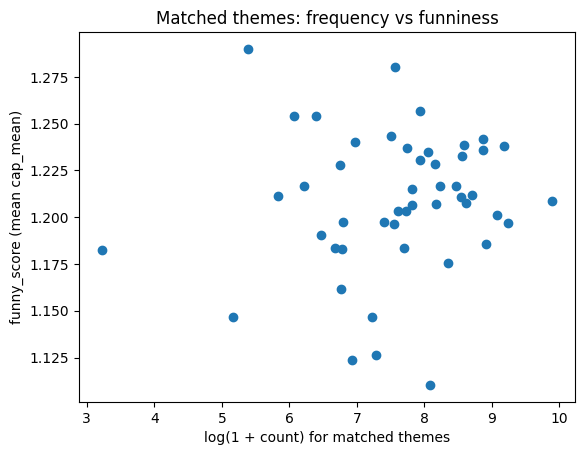

In [24]:
q1_null_hypothesis = "There is no correlation between the frequency of matched themes in image-caption pairs and their funniness score."
q1_alpha = 0.05

# extract diag
diag = cells[(cells['image_theme_id'] == cells['caption_theme_id']) & (cells['count'] > 0)].copy()
diag['log_count'] = np.log1p(diag['count'])

# ensure numeric and drop NaNs
x = pd.to_numeric(diag['log_count'], errors='coerce')
y = pd.to_numeric(diag['funny_score'], errors='coerce')
mask = x.notna() & y.notna()
x = x[mask].to_numpy()
y = y[mask].to_numpy()

# compute spearman and pearson
spearman_res = stats.spearmanr(x, y)
pearson_res  = stats.pearsonr(x, y)

spearman_r, spearman_p = float(spearman_res.statistic), float(spearman_res.pvalue)
pearson_r,  pearson_p  = float(pearson_res.statistic),  float(pearson_res.pvalue)

print(f"Diagonal (matched themes) with count>0: n={len(x)}")
print(f"Spearman r={spearman_r:.3f}, p={spearman_p:.3g}")
print(f"Pearson  r={pearson_r:.3f}, p={pearson_p:.3g}")

# Quick visualization
plt.figure()
plt.scatter(x, y)
plt.xlabel('log(1 + count) for matched themes')
plt.ylabel('funny_score (mean cap_mean)')
plt.title('Matched themes: frequency vs funniness')
plt.show()


In [32]:
print(f"Null hypothesis:\n {q1_null_hypothesis}\n")

# test hypothesis
if spearman_p < q1_alpha:
    print(f"Reject null hypothesis at alpha={q1_alpha} with p={spearman_p:.3g}: significant correlation found.")
else:
    print(f"Fail to reject null hypothesis at alpha={q1_alpha} with p={spearman_p:.3g}: no significant correlation found.")

Null hypothesis:
 There is no correlation between the frequency of matched themes in image-caption pairs and their funniness score.

Fail to reject null hypothesis at alpha=0.05 with p=0.326: no significant correlation found.


From this result, we can say most surely that there are no appearant correlations between the funny_score and how frequent a theme is being used: both correlation tests were small and non significat. There are no evidence of a monotonic or linear association between frequency and funniness among matched themes at alpha = 0.05. 

Take-away: following the 'trends' doesn’t reliably buy you extra laughs, at least not in a way we can detect here.

## Q2: Are some image themes inherently funnier?

Here we will test whether image theme predicts caption funniness **after controlling for caption theme**, using contest-clustered standard errors.


Note: this following cell takes some time to run: ~ 2min30s

In [26]:
q2_null_hypothesis = "After controlling for caption theme, image theme has no effect on caption funniness"
q2_alpha = 0.05

# Caption-level model with theme fixed effects and contest-clustered SE
m_img = smf.ols('cap_mean ~ C(image_theme_id) + C(caption_theme_id)', data=pairs).fit(
    cov_type='cluster', cov_kwds={'groups': pairs['contest_id']}
)

# joint Wald test for Image Theme block
# Collect all image-theme dummy coefficient names (excluding intercept and the baseline level)
img_terms = [name for name in m_img.params.index if name.startswith("C(image_theme_id)[T.")]

wald_img = m_img.wald_test(img_terms)   # joint test: all these coefficients == 0
q2_p = float(wald_img.pvalue)


/opt/miniconda3/envs/ada/lib/python3.13/site-packages/statsmodels/base/model.py:1912: FutureWarning:

The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.



In [27]:
print(f"Null hypothesis:\n {q2_null_hypothesis}\n")
# print(f"Joint Wald test (ImageTheme block): chi2={float(wald_img.statistic):.3f}, df={int(wald_img.df_denom)}, p={q2_p:.3g}")

if q2_p < q2_alpha:
    print(f"Rejected successfully null hypothesis at alpha={q2_alpha} with p={q2_p}: image themes differ in funniness (given caption-theme control).")
else:
    print(f"Fail to reject null hypothesis at alpha={q2_alpha} with p={q2_p:.3g}: no evidence of image-theme differences (given caption-theme controls).")

Null hypothesis:
 After controlling for caption theme, image theme has no effect on caption funniness

Rejected successfully null hypothesis at alpha=0.05 with p=0.0: image themes differ in funniness (given caption-theme control).


Ah-ha ! Some image captions are thus inherently funnier than others.

The joint Wald test on the Image Theme block strongly rejects the null hypothesis that image themes have no effect on funniness after controlling for caption theme (p << 0.001, printed as 0.0 due to rounding). In short: even when we hold the caption theme constant, the image theme still shifts expected funniness, meaning some subjects are just naturally better “comedy ladders” than others.

Take-away: you can be equally witty, but if you’re joking on a theme the dataset likes, you’re basically starting with a head start (comedy unfairness, confirmed). Some subject are funnier than other independantly of how funny you are, life's unfair I know...

### Q3) Semantic distance: relation with funniness and frequency
This question contains 2 in 1 ! What a deal:
- **Q3a:** Does semantic distance predict funniness (controlling for image & caption themes)?
- **Q3b:** Does semantic distance predict frequency of occurrence (controlling for marginal popularity of themes)?

In [28]:
# similarity wide -> long
sim_long = p3_utils.similarity_wide_to_long(similarity_df)

# merge similarity into pairs and cells
pairs_sim = p3_utils.add_similarity_to_theme_pairs(pairs, sim_long)
cells_sim = p3_utils.add_similarity_to_theme_pairs(cells, sim_long)


In [30]:
# Q3a
q3a = p3_utils.fit_q3a_distance_predicts_funniness(pairs_sim)
print("Q3a distance coef:", q3a.distance_coef, "p:", q3a.distance_pvalue)

q3a_null_hypothesis = "Semantic distance between image and caption themes does not predict caption funniness after controlling for image theme and caption theme (distance coefficient = 0)."
q3a_alpha = 0.05

# Decision statements
if q3a.distance_pvalue < q3a_alpha:
    print(f"Reject null hypothesis at alpha={q3a_alpha}: semantic distance is significantly associated with funniness (given controls).")
else:
    print(f"Fail to reject null hypothesis at alpha={q3a_alpha}: no evidence that semantic distance predicts funniness (given controls).")

Q3a distance coef: -0.0077404364831072 p: 0.0893741774565763
Fail to reject null hypothesis at alpha=0.05: no evidence that semantic distance predicts funniness (given controls).


Okay so, “the weirder the pairing, the funnier the caption” might actually not hold up.

The verdict is ... meh:

The distance coefficient is slightly negative (beta ~ −0.0077) and the p-value (0.089) is in that awkward “almost, but not really” zone. So at alpha=0.05 we don’t have strong evidence that semantic distance reliably boosts funniness once we control for themes.

Also let's observe that the distance coefficient is negative. That means that as image and caption themes get more semantically different, the outcome goes down: here it suggests “more mismatch => slightly less funny” (and here it’s weak/not significant at 0.05).

Take-away: just making the caption theme far away from the image theme doesn’t automatically make it funnier. At the end chaos is not a guaranteed comedy strategy.

In [31]:
# Q3b
q3b = p3_utils.fit_q3b_distance_predicts_frequency(cells_sim)
print("Q3b distance coef:", q3b.distance_coef, "p:", q3b.distance_pvalue)

q3b_null_hypothesis = "to complete"
q3b_alpha = 0.05

# Decision statements
if q3b.distance_pvalue < q3b_alpha:
    print(f"Reject null hypothesis at alpha={q3b_alpha}: semantic distance is significantly associated with frequency (given controls).")
else:
    print(f"Fail to reject null hypothesis at alpha={q3b_alpha}: no evidence that semantic distance predicts frequency (given controls).")

/opt/miniconda3/envs/ada/lib/python3.13/site-packages/statsmodels/genmod/families/family.py:1367: ValueWarning:

Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.



Q3b distance coef: -4.645619998350211 p: 1.965116086927504e-158
Reject null hypothesis at alpha=0.05: semantic distance is significantly associated with frequency (given controls).


But for question 3b, the data does have strong opinions about how often people go for unrelated themes compared to the image one.

Here, the result is loud and clear: semantic distance is very (a lot) strongly associated with frequency (p ~ 0.0), and the coefficient is negative (beta ~ −4.65). Here the negative coeficient clearly shows “more mismatch => much less frequent,” which directly answers whether semantic distance affects funniness and how often people actually make those pairings. Translation: the more semantically distant a caption theme is from the image theme, the less often that pairing happens.

Take-away: contestants mostly play it safe and stay semantically “close”. Wild cross-theme pairings are rare creatures (even if they occasionally land).
